# Painel espacial --- prática

**Curso de Econometria Espacial**  
Prof. Pedro Amaral · Cedeplar/UFMG  

Dados: *NCOVR* (homicídios em condados dos EUA) via `libpysal.examples`.  
Estimadores: classes de painel e SUR do `spreg` (a partir da versão 1.9.1).


## 1. Importações

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

import libpysal
from libpysal.weights import Queen
import spreg

print('spreg', spreg.__version__)


spreg 1.9.1


## 2. Dados: NCOVR (recorte da Costa Leste)

O exemplo `NCOVR` traz taxas de homicídio (`HR`) e covariáveis em três décadas
(1970, 1980, 1990) para 3085 condados.  
Para a prática, restringimos aos estados da Costa Leste (`STFIPS`) — amostra menor,
mesmo desenho espacial.

Variável dependente: `HR70`, `HR80`, `HR90`.  
Explicativas: `RD` (resource deprivation) e `PS` (population structure) nos mesmos anos.


In [2]:
libpysal.examples.load_example('NCOVR')
shp_path = libpysal.examples.get_path('NAT.shp')
dfs = gpd.read_file(shp_path)
print(dfs.shape)
print('CRS:', dfs.crs)
dfs[['NAME', 'STFIPS', 'HR70', 'HR80', 'HR90', 'RD70', 'PS70']].head()


(3085, 70)
CRS: EPSG:4326


,NAME,STFIPS,HR70,HR80,HR90,RD70,PS70
0,Lake of the Woods,27,0.000000,8.855827,0.000000,-0.196536,-1.462559
1,Ferry,53,0.000000,17.208742,15.885624,-0.847856,-1.697720
2,Stevens,53,1.915158,3.450775,6.462453,-0.225283,-0.591883
3,Okanogan,53,1.288643,3.263814,6.996502,-0.391126,-0.552016
4,Pend Oreille,53,0.000000,7.770008,7.478033,-0.451457,-1.181754


In [3]:
# Filtrando apenas costa leste para reduzir N
east_fips = [9, 10, 11, 12, 13, 23, 24, 25, 33, 34, 36, 37, 42, 44, 45, 50, 51, 54]
gdf = dfs[dfs['STFIPS'].isin(east_fips)].copy().set_index('FIPSNO', drop=False)
print(gdf.shape)


(789, 70)


## 3. Matriz de pesos Rainha

In [4]:
w = Queen.from_dataframe(gdf, ids='FIPSNO', use_index=False)
print(w.n, 'observações')
print('Ilhas:', w.islands)
w.transform = 'r'
print('Transformação:', w.transform)
print('CRS estimado:', gdf.estimate_utm_crs())


789 observações
Ilhas: []
Transformação: R
CRS estimado: EPSG:32618


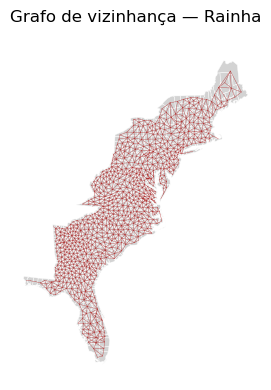

In [5]:
gdf = gdf.to_crs(epsg=32618)

fig, ax = plt.subplots(figsize=(4, 4))
gdf.plot(ax=ax, facecolor='lightgray', edgecolor='white', linewidth=0.3)
w.plot(gdf, ax=ax,
             edge_kws=dict(color='firebrick', linewidth=0.25, alpha=0.5),
             node_kws=dict(marker=''))
ax.set_title('Grafo de vizinhança — Rainha')
ax.set_axis_off()
plt.tight_layout()
plt.show()


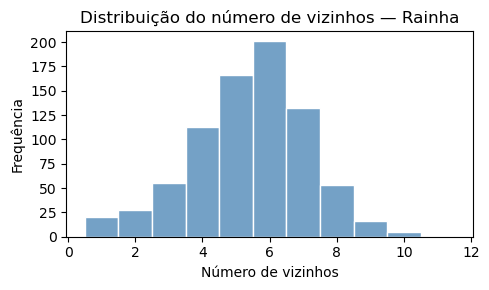

count    789.000000
mean       5.424588
std        1.736720
min        1.000000
25%        4.000000
50%        6.000000
75%        7.000000
max       11.000000
Name: n_vizinhos, dtype: float64


In [6]:
card = pd.Series(w.cardinalities, name='n_vizinhos')

fig, ax = plt.subplots(figsize=(5, 3))
sns.histplot(card, bins=range(int(card.min()), int(card.max()) + 2),
             discrete=True, color='steelblue', edgecolor='white', ax=ax)
ax.set_xlabel('Número de vizinhos')
ax.set_ylabel('Frequência')
ax.set_title('Distribuição do número de vizinhos — Rainha')
ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

print(card.describe())

## 4. Formato *wide*

As classes de painel do `spreg` aceitam o painel em formato **wide** ou **long**.
Aqui usamos wide: cada variável aparece com $T$ colunas lado a lado, **na ordem temporal**.

- `y[:, 0]` é $t=0$ (1970), `y[:, 1]` é $t=1$ (1980), etc.
- `x[:, 0:T]` são os $T$ períodos da primeira explicativa;
  `x[:, T:2T]` os da segunda.


In [7]:
y_var = gdf[['HR70', 'HR80', 'HR90']]
x_var = gdf[['RD70', 'RD80', 'RD90', 'PS70', 'PS80', 'PS90']]
print('y:', y_var.shape, '| x:', x_var.shape)
y_var.head()


y: (789, 3) | x: (789, 6)


,HR70,HR80,HR90
FIPSNO,,,
23003,1.062948,2.554810,1.150271
23025,0.821079,5.922241,0.669788
23021,4.093747,7.561151,5.361068
23019,2.658309,3.892518,2.046371
23029,6.698148,2.860166,4.720366


## 5. Pooled OLS

$$Y = X\beta + \varepsilon, \qquad \varepsilon \sim (0,\sigma^2 I_{NT})$$

`spat_diag=True` calcula os testes BSK (Baltagi, Song e Koh):
LM1 (efeito aleatório), LM2 (dependência espacial) e LMJ (conjunto).

`time_effects=True` acrescenta dummies de tempo.


In [8]:
pooled_t = spreg.PooledOLS(y=y_var, x=x_var, w=w, spat_diag=True, time_effects=True)
print(pooled_t.summary)


REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: POOLED OLS PANEL WITH TIME DUMMIES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :          HR                Number of Observations:        2367
Mean dependent var  :      8.8420                Number of Variables   :           5
S.D. dependent var  :      7.4372                Degrees of Freedom    :        2362
R-squared           :      0.3666
Adjusted R-squared  :      0.3655
Sum squared residual:     82891.8                F-statistic           :    341.7606
Sigma-square        :      35.094                Prob(F-statistic)     :  2.658e-232
S.E. of regression  :       5.924                Log likelihood        :   -7567.051
Sigma-square ML     :      35.020                Akaike info criterion :   15144.102
S.E of regression ML:      5.9178                Schwarz criterion     :   15172.949

-----

### Interpretação — pooled com efeitos temporais

$$
HR_{it} = \beta_0 + \beta_{1} RD_{it} + \beta_{2} PS_{it} + \delta_2 D_{80} + \delta_3 D_{90} + \varepsilon_{it}.
$$

#### Testes BSK

O pooled impõe $\sigma_\mu^2=0$ e ausência de dependência espacial. Baltagi, Song e Koh (2003) testam as duas restrições.

| Teste | $H_0$ | Estatística | $p$ |
|---|---|---:|---:|
| LM1 (marginal RE) | $\sigma_\mu^2=0$ | $13{,}67$ | $<0{,}001$ |
| LM2 (marginal espacial) | sem dependência espacial no erro | $19{,}77$ | $<0{,}001$ |
| LMJ (conjunto) | as duas restrições | $577{,}47$ | $<0{,}001$ |

As três hipóteses são rejeitadas.

- **LM1**: há heterogeneidade individual persistente. O pooled é ineficiente (e, se $\mu_i$ correlaciona com $X$, inconsistente).
- **LM2**: os resíduos são espacialmente correlacionados. A inferência do MQO empilhado não é válida; se o processo for de lag, $\hat\beta$ também é inconsistente.
- **LMJ**: rejeita o modelo clássico de uma vez. O valor muito acima de $\mathrm{LM1}+\mathrm{LM2}$ é o padrão quando os dois desvios operam juntos.

Conclusão: não permanecer no pooled. Estimar FE e RE (Hausman) e as versões com $W$ (SEM/SAR no painel).

## 6. Efeitos aleatórios (GLS)

$$Y = X\beta + v, \qquad v = (\iota_T \otimes I_N)\mu + \varepsilon$$

`PanelRE` estima as componentes de variância (Swamy--Arora) e, no `summary`, reporta o Hausman espacial.


In [9]:
re = spreg.PanelRE(y=y_var, x=x_var, w=w, spat_diag=True, time_effects=True)
print(re.summary)


REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: RANDOM EFFECTS PANEL (TWO-WAY)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :          HR                Number of Observations:        2367
Mean dependent var  :      8.8420                Number of Variables   :           5
S.D. dependent var  :      7.4372                Degrees of Freedom    :        2362
Pseudo R-squared    :      0.3663
Sum squared residual:     83069.7                F-statistic           :    304.2376
Sigma-square        :      24.634                Prob(F-statistic)     :  2.904e-211
S.E. of regression  :       4.963                Log likelihood        :   -7569.587
Sigma-square ML     :      24.634                Akaike info criterion :   15149.175
S.E of regression ML:      4.9633                Schwarz criterion     :   15178.021

-------------------------------------------

### Interpretação — efeitos aleatórios two-way

$$
HR_{it} = \beta_0 + \beta_{1} RD_{it} + \beta_{2} PS_{it} + \delta_2 D_{80} + \delta_3 D_{90} + \mu_i + \varepsilon_{it},
\qquad \mathrm{Cov}(\mu_i,X_{it})=0.
$$

#### Componentes de variância

| Componente | Estimativa |
|---|---:|
| $\hat\sigma_\varepsilon^2$ (idiosincrática) | $23{,}66$ |
| $\hat\sigma_\mu^2$ (individual) | $10{,}36$ |
| $\hat\theta$ (peso do quasi-desvio) | $0{,}343$ |

A transformação GLS é $y_{it}(\theta)=y_{it}-\theta\,\bar y_i$, com
$$
\theta = 1 - \frac{\sigma_\varepsilon}{\sqrt{T\sigma_\mu^2+\sigma_\varepsilon^2}}.
$$
Aqui $T=3$, $\hat\sigma_1^2=T\hat\sigma_\mu^2+\hat\sigma_\varepsilon^2\approx 54{,}73$ e $\hat\theta\approx 0{,}343$: nem pooled ($\theta=0$) nem *within* completo ($\theta=1$). Cerca de $10{,}36/(10{,}36+23{,}66)\approx 30\%$ da variância do composto é permanente na unidade.

#### Testes

| Teste | $H_0$ | Estatística | gl | $p$ |
|---|---|---:|---:|---:|
| Hausman | $\mathrm{Cov}(\mu_i,X_{it})=0$ (RE consistente) | $104{,}88$ | $4$ | $<0{,}001$ |
| LM espacial condicional | sem dependência espacial **dado** o RE | $11{,}39$ | $1$ | $<0{,}001$ |

O Hausman rejeita: $\mu_i$ correlaciona com $RD$ e/ou $PS$. O RE é inconsistente; a parametrização adequada entre FE e RE é o **efeito fixo** (se hipóteses válidas) (Lee e Yu, 2012).

O LM condicional rejeita aleatoriedade espacial *depois* de permitir $\mu_i$. O RE não espacial não esgota o problema: falta $W$ (SEM ou SAR no painel).

Síntese: sair do RE clássico. Preferir FE e, sobre o FE, as especificações com defasagem espacial em $y$ ou no erro.

## 7. Efeitos fixos (*within*)

$$Y = (\iota_T \otimes I_N)\mu + X\beta + \varepsilon$$

A transformação *within* remove $\mu_i$. Com `time_effects=True` o modelo é two-way.


In [10]:
fe = spreg.PanelFE(y=y_var, x=x_var, w=w, time_effects=True)
print(fe.summary)


REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: FIXED EFFECTS PANEL (TWO-WAY)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :          HR                Number of Observations:        2367
Mean dependent var  :      8.8420                Number of Variables   :           4
S.D. dependent var  :      7.4372                Degrees of Freedom    :        2363
Pseudo R-squared    :      0.7154
Sum squared residual:     37242.6                F-statistic           :   1980.1123
Sigma-square        :      23.661                Prob(F-statistic)     :           0
S.E. of regression  :       4.864                Log likelihood        :   -6620.153
Sigma-square ML     :      15.734                Akaike info criterion :   13248.306
S.E of regression ML:      3.9666                Schwarz criterion     :   13271.384
Individual FE mean  :     13.2519

----------

In [11]:
# $\hat\mu_i$ das cinco primeiras unidades (lembrar do parâmetro incidental -> inconsistência)
fe.fixed_effects[:5]


array([[3.74145206],
       [2.07285211],
       [0.11815978],
       [9.14970737],
       [3.50770994]])

## 8. SEM no painel 
### 8.1 FE - SEM

In [12]:
sem_fe = spreg.ML_ErrorFE(y=y_var, x=x_var, w=w, time_effects=True)
print(sem_fe.summary)


REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ML SPATIAL ERROR PANEL MODEL - FIXED EFFECTS WITH TIME EFFECTS
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :          HR                Number of Observations:        2367
Mean dependent var  :      0.0000                Number of Variables   :           4
S.D. dependent var  :      4.0669                Degrees of Freedom    :        2363
Pseudo R-squared    :      0.0482
Log likelihood      :  -6603.0402
Sigma-square ML     :     15.4047                Akaike info criterion :   13214.080
S.E of regression   :      3.9249                Schwarz criterion     :   13237.158
Individual FE mean  :     13.0962

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
----------------------------

### 8.2 RE - SEM: GMM (KKP)

`GM_ErrorRE` é o estimador de Kapoor, Kelejian e Prucha (2007). Não assume distribuição normal.

In [13]:
kkp = spreg.GM_ErrorRE(y=y_var, x=x_var, w=w, time_effects=True)
print(kkp.summary)


REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: GMM SPATIAL ERROR PANEL MODEL - RANDOM EFFECTS (KKP) WITH TIME EFFECTS
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :          HR                Number of Observations:        2367
Mean dependent var  :      8.8420                Number of Variables   :           5
S.D. dependent var  :      7.4372                Degrees of Freedom    :        2362
Pseudo R-squared    :      0.3658

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
            CONSTANT         8.00947         0.36223        22.11171         0.00000
                  RD         4.33873         0.17675        24.54686         0.00000
   

### 8.3 RE - SEM máxima verossimilhança (Baltagi / Anselin)

$$u = \lambda(I_T \otimes W_N)u + \varepsilon$$

O processo espacial está só na inovação idiosincrática; $\mu_i$ permanece
espacialmente não correlacionado. Assume distribuição normal.


In [14]:
sem_re = spreg.ML_ErrorRE(y=y_var, x=x_var, w=w, time_effects=True)
print(sem_re.summary)


REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ML SPATIAL ERROR PANEL MODEL (SEM) - RANDOM EFFECTS WITH TIME EFFECTS
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :          HR                Number of Observations:        2367
Mean dependent var  :      8.8420                Number of Variables   :           5
S.D. dependent var  :      7.4372                Degrees of Freedom    :        2362
Pseudo R-squared    :      0.3662

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
            CONSTANT         7.97586         0.34060        23.41702         0.00000
                  RD         4.40256         0.17082        25.77277         0.00000
    

## 9. SAR no painel — máxima verossimilhança

$$Y = \rho(I_T \otimes W_N)Y + X\beta + v$$

### 9.1. SAR - FE


In [15]:
sar_fe = spreg.ML_LagFE(y=y_var, x=x_var, w=w, time_effects=True)
print(sar_fe.summary)


REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ML SPATIAL LAG PANEL - FIXED EFFECTS WITH TIME EFFECTS
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :          HR                Number of Observations:        2367
Mean dependent var  :      0.0000                Number of Variables   :           5
S.D. dependent var  :      4.0669                Degrees of Freedom    :        2362
Pseudo R-squared    :      0.0684
Log likelihood      :  -6603.2997
Sigma-square ML     :     15.4124                Akaike info criterion :   13216.599
S.E of regression   :      3.9259                Schwarz criterion     :   13245.446
Individual FE mean  :     11.1174

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------

In [16]:
sar_fe.fixed_effects[:5]


array([[2.76615386],
       [1.55072091],
       [0.29991187],
       [7.93198396],
       [3.20451278]])

### 9.2 RE

In [17]:
sar_re = spreg.ML_LagRE(y=y_var, x=x_var, w=w, time_effects=True)
print(sar_re.summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ML SPATIAL LAG PANEL - RANDOM EFFECTS WITH TIME EFFECTS
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :          HR                Number of Observations:        2367
Mean dependent var  :      6.5463                Number of Variables   :           7
S.D. dependent var  :      6.1475                Degrees of Freedom    :        2360
Pseudo R-squared    :      0.3699
Log likelihood      :  -7379.9922
Sigma-square ML     :     23.8393                Akaike info criterion :   14773.984
S.E of regression   :      4.8826                Schwarz criterion     :   14814.370

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
---------------------------------------------------------------------

### Escolha entre SEM-FE e SAR-FE (two-way)

O Hausman do RE descartou o efeito aleatório. Restam SEM-FE e SAR-FE, ambos two-way. Na ausência dos testes específicos e suas versões robustas no `spreg`, podemos olhar os critérios de informação:

|  | SEM-FE | SAR-FE |
|---|---:|---:|
| $\ell$ | $-6603{,}04$ | $-6603{,}30$ |
| AIC | $13214{,}1$ | $13216{,}6$ |
| BIC | $13237{,}2$ | $13245{,}4$ |
| parâmetro espacial | $\hat\lambda=0{,}185$ $(z=6{,}18)$ | $\hat\rho=0{,}181$ $(z=6{,}13)$ |

O ajuste é indistinguível. Critérios de informação **não** decidem.

O que decide é a **consequência da omissão** (aula de especificação):

- se o DGP tem $\mathbf{Wy}$ e estima-se SEM (ou FE sem $W$), $\hat\beta$ é inconsistente;
- se o DGP tem só $\mathbf{Wu}$ e estima-se SAR, $\hat\beta$ permanece consistente (há perda de eficiência e $\rho$ “absorve” parte do erro).

Como $\hat\rho$ é fortemente significativo no SAR-FE e não há LM robusto de painel que limpe a ambiguidade, o modelo a reter é o **SAR-FE**. Entre viesar $\beta$ e perder um pouco de eficiência, evita-se o viés.

#### Resultados do SAR-FE (modelo retido)

$$
HR_{it}
= \rho\sum_j w_{ij}HR_{jt}
+ \beta_{1} RD_{it}
+ \beta_{2} PS_{it}
+ \delta_2 D_{80}+\delta_3 D_{90}
+ \mu_i+\varepsilon_{it}.
$$

A média de $HR$ no output é zero: estimação *within*. $\hat\beta$ **não** é o efeito marginal.

| Variável | $\hat\beta$ | $p$ | Direto | Total |
|---|---:|---:|---:|---:|
| $RD$ | $0{,}508$ | $0{,}149$ | $0{,}508$ | $0{,}620$ |
| $PS$ | $-6{,}927$ | $<0{,}001$ | $-6{,}927$ | $-8{,}456$ |
| `time_2` | $-0{,}587$ | $0{,}003$ | $-0{,}587$ |  $-0{,}716$ |
| `time_3` | $-0{,}448$ | $0{,}029$ | $-0{,}448$ |  $-0{,}546$ |
| $W\_HR$ ($\rho$) | $0{,}181$ | $<0{,}001$ | — | — |

Impactos *simple* (Anselin): direto $=\beta$, total $=\beta/(1-\hat\rho)$, indireto $=$ total $-$ direto. $\hat\rho=0{,}181$ implica multiplicador $1/(1-0{,}181)\approx 1{,}22$.

- **$\rho$**: interação contemporânea nas taxas. O que ocorre no condado vizinho desloca $HR_i$ e reentra em $i$ pelo feedback.
- **$RD$**: efeito *within* não significativo (direto nem total). O coeficiente grande e positivo do pooled era variação *entre* condados, absorvida por $\mu_i$.
- **$PS$**: sinal invertido em relação ao pooled. Condicional a $\mu_i$, um aumento da estrutura populacional no próprio condado reduz $HR$ em $6{,}93$ pontos (direto) e, via vizinhos, mais $1{,}53$ (indireto); total $-8{,}46$.
- **Períodos**: 1980 e 1990 abaixo de 1970, já com $\mu_i$ e o multiplicador.

#### SEM-FE frente aos totais do SAR

No SEM, $\hat\beta$ **é** o efeito parcial (não há canal de $X$ via $W$). A comparação honesta com o SAR é $\hat\beta_{\mathrm{SEM}}$ versus o **total** do SAR.

| Variável | $\hat\beta$ SEM-FE | Total SAR-FE |
|---|---:|---:|
| $RD$ | $0{,}575$ | $0{,}620$ |
| $PS$ | $-7{,}50$ | $-8{,}46$ |
| `time_2` | $-0{,}732$ | $-0{,}716$ |
| `time_3` | $-0{,}596$ | $-0{,}546$ |

A ordem de grandeza coincide. O SEM “empacota” no $\beta$ o que o SAR decompõe em direto e indireto; por isso $PS$ no SEM ($-7{,}50$) fica entre o direto do SAR ($-6{,}93$) e o total ($-8{,}46$). Os sinais e a irrelevância de $RD$ *within* não dependem da escolha. O que muda é a leitura: no SEM não há spillover substantivo; no SAR, cerca de $18\%$ do efeito de $PS$ passa pelos vizinhos.

O `Individual FE mean` ($\approx 11$ no SAR) é a média dos $\hat\mu_i$ reconstruídos; com $T=3$ **não** é estimativa consistente de cada $\mu_i$.

## 10. SUR espacial

Agora cada período é uma **equação** com $\beta_t$ próprio e covariância do erro
entre períodos ($N>T$).  Ou seja, enquanto os paineis por efeitos fixos ou aleatórios assumem que os $\beta$ são constantes durante todo o período em análise, os modelos SUR permitem sua variação.
Usamos o mesmo recorte, com três equações: 1970, 1980 e 1990.

A API do SUR aceita **listas de nomes** + o `DataFrame`.


In [18]:
y_sur = ['HR70', 'HR80', 'HR90']
x_sur = [['RD70', 'PS70'], ['RD80', 'PS80'], ['RD90', 'PS90']]


### 10.1 SUR clássico (sem $W$ na média)

`spat_diag=True` apresenta LM de erro e de lag.


In [19]:
sur = spreg.SUR(
    y_sur, x_sur, df=gdf, w=w,
    spat_diag=True, name_ds='NCOVR-East', name_w='Queen'
)
print(sur.summary)


REGRESSION
----------
SUMMARY OF OUTPUT: SEEMINGLY UNRELATED REGRESSIONS (SUR)
--------------------------------------------------------
Data set            :  NCOVR-East
Weights matrix      :       Queen
Number of Equations :           3                Number of Observations:         789
Log likelihood (SUR):   -7388.151                Number of Iterations  :           1
----------

SUMMARY OF EQUATION 1
---------------------
Dependent Variable  :        HR70                Number of Variables   :           3
Mean dependent var  :      9.4243                Degrees of Freedom    :         786
S.D. dependent var  :      8.6750

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
          Constant_1       8.1522947       0.3298212      24.7173135       0.0000000
                RD70     

### Interpretação — SUR clássico (três equações)

Cada período é uma equação com $\boldsymbol{\beta}_t$ próprio ($N=789$, $T=3$). O SUR explora $\Sigma=\mathrm{Cov}(\varepsilon_t,\varepsilon_s)$ entre períodos; $W$ entra só nos diagnósticos.

#### Testes sobre $\Sigma$

| Teste | $H_0$ | Estatística | gl | $p$ |
|---|---|---:|---:|---:|
| LM sobre $\Sigma$ | $\sigma_{ts}=0$ para $t\neq s$ (OLS equação a equação) | $218{,}3$ | $3$ | $<0{,}001$ |
| LR sobre $\Sigma$ | a mesma | $199{,}6$ | $3$ | $<0{,}001$ |

$\mathrm{gl}=T(T-1)/2=3$. Rejeição: os erros dos três cortes **não** são independentes. Estimar três MQO separados desperdiça a covariância; o SUR é justificado.

#### Matriz de correlação dos erros

|  | 1970 | 1980 | 1990 |
|---|---:|---:|---:|
| 1970 | $1$ | $0{,}327$ | $0{,}246$ |
| 1980 | $0{,}327$ | $1$ | $0{,}331$ |
| 1990 | $0{,}246$ | $0{,}331$ | $1$ |

Correlação contemporânea *entre períodos* da mesma unidade, da ordem de $0{,}25$–$0{,}33$. O ganho do SUR vem daí: um choque omitido em 1970 permanece, em parte, em 1980 e 1990.

#### Chow — constância de $\beta$ entre equações

| Restrição | gl | Estatística | $p$ |
|---|---:|---:|---:|
| interceptos iguais | $2$ | $9{,}17$ | $0{,}010$ |
| $\beta_{RD}$ iguais | $2$ | $6{,}27$ | $0{,}043$ |
| $\beta_{PS}$ iguais | $2$ | $7{,}72$ | $0{,}021$ |

As três restrições caem a $5\%$. $\boldsymbol{\beta}$ **não** é estável em $t$: pooled com $\beta$ comum (mesmo o two-way da seção anterior) é uma média de regimes distintos. O SUR com $\boldsymbol{\beta}_t$ é a parametrização correta nessa dimensão.

(Os pontos: $\hat\beta_{RD}$ fica em $4{,}10$–$4{,}63$; $\hat\beta_{PS}$ sobe de $0{,}70$ em 1970 para $1{,}65$ em 1990.)

#### Dependência espacial no sistema

| Teste | gl | Estatística | $p$ |
|---|---:|---:|---:|
| LM-erro (SUR) | $3$ | $214{,}2$ | $<0{,}001$ |
| LM-lag (SUR) | $3$ | $1393{,}9$ | $<0{,}001$ |

Ambos rejeitam. O LM-lag é cerca de **seis vezes** o LM-erro: a evidência de $\mathbf{Wy}_t$ em cada equação é muito mais forte do que a de $\mathbf{Wu}_t$.

Leitura conjunta com a aula de especificação: o SUR clássico ainda está mal especificado no espaço. O próximo passo é o **SUR-lag** (`SURlagIV` / MQ3E), não o SUR-erro.

### 10.2 SUR-lag (MQ3E / IV)

`SURlagIV` instrumenta $\mathbf{Wy}_t$ com $\mathbf{WX}_t$
(e instrumentos adicionais, se houver). 


In [20]:
sur_lag = spreg.SURlagIV(
    y_sur, x_sur, w=w, df=gdf,
    spat_diag=True, name_ds='NCOVR-East', name_w='Queen'
)
print(sur_lag.summary)


REGRESSION
----------
SUMMARY OF OUTPUT: SEEMINGLY UNRELATED REGRESSIONS (SUR) - SPATIAL LAG MODEL
----------------------------------------------------------------------------
Data set            :  NCOVR-East
Weights matrix      :       Queen
Number of Equations :           3                Number of Observations:         789
----------

SUMMARY OF EQUATION 1
---------------------
Dependent Variable  :        HR70                Number of Variables   :           4
Mean dependent var  :      9.4243                Degrees of Freedom    :         785
S.D. dependent var  :      8.6750

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
          Constant_1       5.6957052       0.8442825       6.7462079       0.0000000
                RD70       3.6539607       0.4408642       8.2881770  

### Interpretação — SUR-lag (MQ3E)

Cada período é um SAR com $\boldsymbol{\beta}_t$ e $\rho_t$ próprios. $\mathbf{Wy}_t$ é instrumentado por $\mathbf{WX}_t$ ($W\_RD_t$, $W\_PS_t$); o terceiro estágio usa $\hat\Sigma$.

$$
HR_{t} = \rho_t W\, HR_{t} + \beta_{0t} + \beta_{RD,t} RD_{t} + \beta_{PS,t} PS_{t} + \varepsilon_{t}.
$$

| Equação | $\hat\beta_{RD}$ | $\hat\beta_{PS}$ | $\hat\rho$ | $p(\rho)$ |
|---|---:|---:|---:|---:|
| 1970 | $3{,}65$ | $0{,}70$ | $0{,}281$ | $0{,}002$ |
| 1980 | $3{,}58$ | $1{,}18$ | $0{,}221$ | $<0{,}001$ |
| 1990 | $4{,}49$ | $1{,}68$ | $0{,}073$ | $0{,}309$ |

$\hat\rho$ cai ao longo do tempo e deixa de ser significativo em 1990. $RD$ e $PS$ permanecem positivos e significativos em todos os cortes.

$\hat\beta$ **não** é o efeito marginal. O total *simple* em cada $t$ é $\beta_t/(1-\rho_t)$ quando $W$ está padronizada em linha. Como `spreg` não informa automaticamente os efeitos multiplicadores, é preciso calcular, usando o $\rho$ de cada equação.

#### Teste conjunto de $\rho$

| Teste | $H_0$ | Estatística | gl | $p$ |
|---|---|---:|---:|---:|
| Significância conjunta de $\rho$ | $\rho_{70}=\rho_{80}=\rho_{90}=0$ | $16{,}65$ | $3$ | $0{,}0008$ |

Rejeição: o bloco $\mathbf{Wy}_t$ entra no sistema, mesmo com $\hat\rho_{90}$ individualmente nulo. Confirma o LM-lag do SUR clássico e justifica o SUR-lag em vez do SUR sem $W$.

#### Chow entre equações

| Restrição | gl | Estatística | $p$ |
|---|---:|---:|---:|
| interceptos iguais | $2$ | $3{,}65$ | $0{,}161$ |
| $\beta_{RD}$ iguais | $2$ | $8{,}72$ | $0{,}013$ |
| $\beta_{PS}$ iguais | $2$ | $8{,}21$ | $0{,}017$ |
| $\rho$ iguais | $2$ | $4{,}64$ | $0{,}098$ |

Com $\mathbf{Wy}_t$ no modelo, os interceptos deixam de diferir. $RD$ e $PS$ **continuam** instáveis em $t$ (em particular $\hat\beta_{PS}$ sobe de $0{,}70$ para $1{,}68$). A igualdade dos três $\rho$ não se rejeita a $5\%$ ($p=0{,}098$): um $\rho$ comum seria admissível, mas não é necessário.

#### Matriz de correlação dos erros

|  | 1970 | 1980 | 1990 |
|---|---:|---:|---:|
| 1970 | $1$ | $0{,}276$ | $0{,}204$ |
| 1980 | $0{,}276$ | $1$ | $0{,}297$ |
| 1990 | $0{,}204$ | $0{,}297$ | $1$ |

As correlações caem em relação ao SUR clássico ($0{,}33$ / $0{,}25$ / $0{,}33$). Parte do que $\Sigma$ capturava era persistência espacial agora absorvida por $\mathbf{Wy}_t$. Ainda assim $\sigma_{ts}\neq 0$: o terceiro estágio continua a ter papel.

Síntese: o sistema é um SUR-lag com $\rho$ relevante em 1970–80 e $\boldsymbol{\beta}$ que muda no tempo.

### 10.3 SUR-erro (MV)

$$u_t = \lambda_t W u_t + \varepsilon_t, \qquad
\mathrm{E}(\varepsilon_t\varepsilon_s')=\sigma_{ts}I_N$$

In [21]:
sur_e = spreg.SURerrorML(
    y_sur, x_sur, w=w, df=gdf,
    spat_diag=True, name_ds='NCOVR-East', name_w='Queen'
)
print(sur_e.summary)


REGRESSION
----------
SUMMARY OF OUTPUT: SEEMINGLY UNRELATED REGRESSIONS (SUR) - ML SPATIAL ERROR MODEL
---------------------------------------------------------------------------------
Data set            :  NCOVR-East
Weights matrix      :       Queen
Number of Equations :           3                Number of Observations:         789
Log likelihood (SUR):   -7385.374
Log likel. (error)  :   -7342.442                Log likel. (SUR error):   -7290.091
----------

SUMMARY OF EQUATION 1
---------------------
Dependent Variable  :        HR70                Number of Variables   :           3
Mean dependent var  :      9.4243                Degrees of Freedom    :         786
S.D. dependent var  :      8.6750

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
          Constant_1      

### 10.4 SUR-erro (GMM)


In [22]:
sur_e_gm = spreg.SURerrorGM(
    y_sur, x_sur, w=w, df=gdf,
    name_ds='NCOVR-East', name_w='Queen'
)
print(sur_e_gm.summary)


REGRESSION
----------
SUMMARY OF OUTPUT: SEEMINGLY UNRELATED REGRESSIONS (SUR) - GM SPATIAL ERROR MODEL
---------------------------------------------------------------------------------
Data set            :  NCOVR-East
Weights matrix      :       Queen
Number of Equations :           3                Number of Observations:         789
----------

SUMMARY OF EQUATION 1
---------------------
Dependent Variable  :        HR70                Number of Variables   :           3
Mean dependent var  :      9.4243                Degrees of Freedom    :         786
S.D. dependent var  :      8.6750

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
          Constant_1       8.2150743       0.4711432      17.4364698       0.0000000
                RD70       4.3162769       0.3564232      12

## 11. Exercício

Encontre a melhor especificação para explicar a taxa de homicídios
(`HR` — homicide rate por 100 mil habitantes) em 1970, 1980 e 1990,
usando como explicativas:

- `FP` — % de famílias abaixo da linha de pobreza;
- `PS` — population structure (componente principal: log da
  população e log da densidade);
- `UE` — taxa de desemprego;
- `FH` — % de domicílios chefiados por mulher.

Considere estimadores de painel com efeitos fixos e aleatórios
(com e sem $W$) e SUR (clássico, erro e lag). Justifique a escolha
com Hausman, LM/LR sobre $\Sigma$, Chow entre equações.